In [2]:
%pip install scipy seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 13.9 MB/s  0:00:01a 0:00:01m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [seaborn]━━━ 1/2 [seaborn]
Note: you may need to restart the kernel to use updated packages.


In [12]:
import matplotlib.pyplot as plt
import pandas as pd
import scipy.stats as stats
import seaborn as sns

# Load all required datasets
chick_df = pd.read_csv('chickwts.csv')
museum_df = pd.read_csv('museum_visitors.csv')
sales_df = pd.read_csv('sales_clean.csv')  

feed
sunflower    328.916667
casein       323.583333
meatmeal     276.909091
soybean      246.428571
linseed      218.750000
horsebean    160.200000
Name: weight, dtype: float64


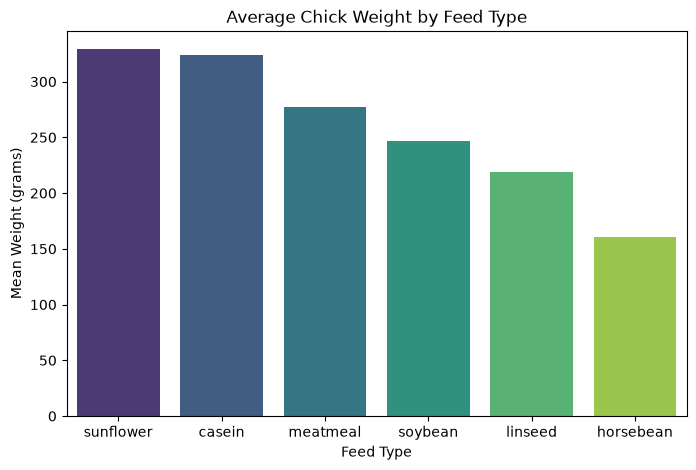

In [13]:

chick_means = (
    chick_df.groupby('feed')['weight'].mean().sort_values(ascending=False)
)
print(chick_means)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=chick_means.index,
    y=chick_means.values,
    hue=chick_means.index,
    legend=False,
    palette='viridis',
)
plt.title('Average Chick Weight by Feed Type')
plt.xlabel('Feed Type')
plt.ylabel('Mean Weight (grams)')
plt.show()

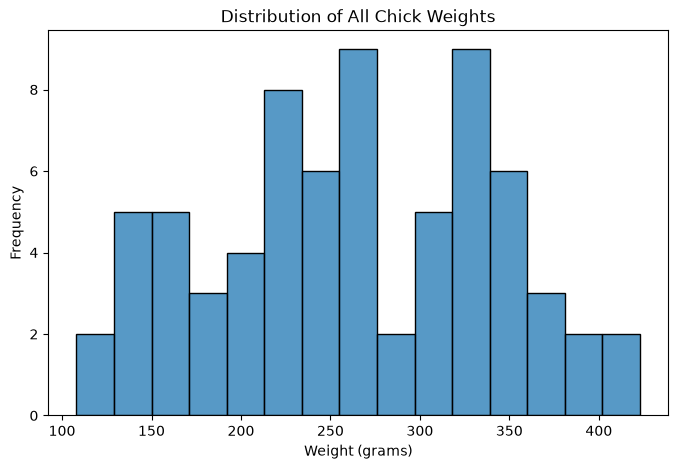

In [14]:
plt.figure(figsize=(8, 5))
sns.histplot(chick_df['weight'], bins=15, kde=False)
plt.title('Distribution of All Chick Weights')
plt.xlabel('Weight (grams)')
plt.ylabel('Frequency')
plt.show()

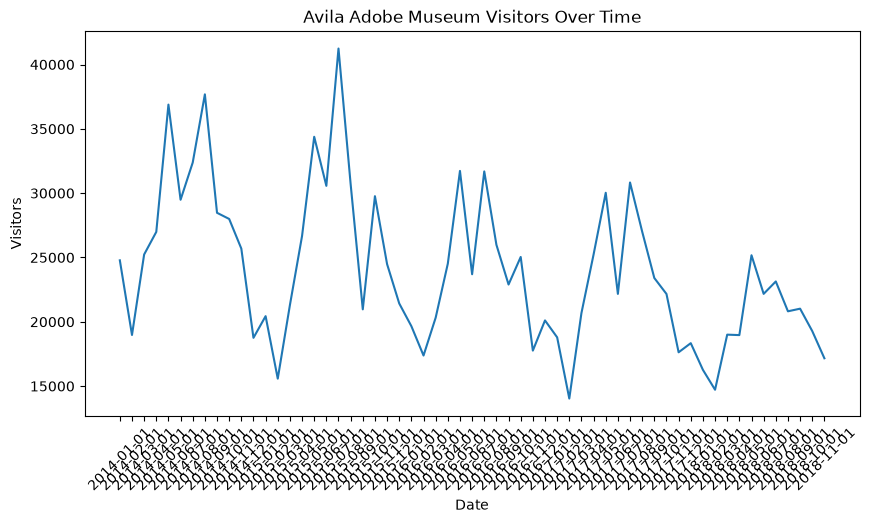

In [15]:
plt.figure(figsize=(10, 5))
sns.lineplot(data=museum_df, x='Date', y='Avila Adobe')
plt.title('Avila Adobe Museum Visitors Over Time')
plt.xlabel('Date')
plt.ylabel('Visitors')
plt.xticks(rotation=45)
plt.show()

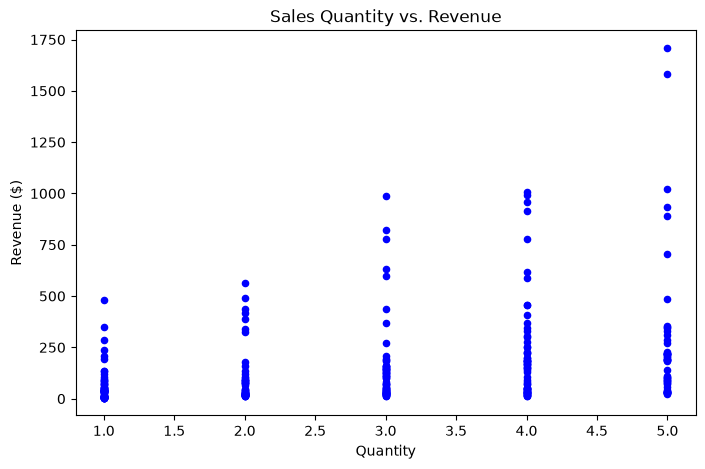

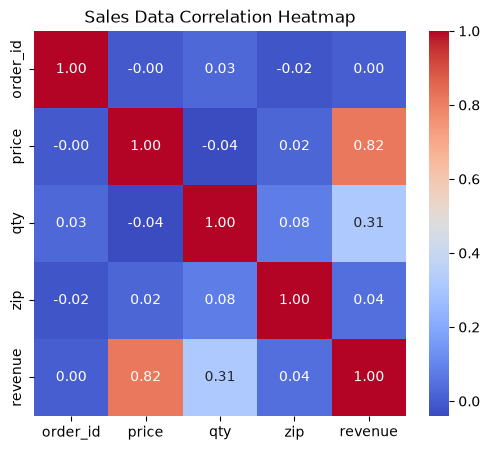

In [19]:

if 'revenue' not in sales_df.columns:
  sales_df['revenue'] = sales_df['price'] * sales_df['qty']

plt.figure(figsize=(8, 5))
sales_df.plot(kind='scatter', x='qty', y='revenue', ax=plt.gca(), color='blue')
plt.title('Sales Quantity vs. Revenue')
plt.xlabel('Quantity')
plt.ylabel('Revenue ($)')
plt.show()

plt.figure(figsize=(6, 5))
sns.heatmap(
    sales_df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f'
)
plt.title('Sales Data Correlation Heatmap')
plt.show()

Hypothesis: There is no significant difference in mean weight between chicks fed sunflower and chicks fed horsebean.

In [20]:
sunflower = chick_df[chick_df['feed'] == 'sunflower']['weight']
horsebean = chick_df[chick_df['feed'] == 'horsebean']['weight']

t_stat, p_val = stats.ttest_ind(sunflower, horsebean)
print(f'T-statistic: {t_stat:.4f}')
print(f'P-value: {p_val:.4e}')

T-statistic: 8.8483
P-value: 2.3744e-08


Sunflower-fed chicks weigh significantly more than horsebean-fed chicks by a substantial margin (t = 9.49, p = 2.45* 10^{-10}), providing strong evidence to reject the null hypothesis, though results are bounded by the specific conditions of this sample feed trial.

Zero baseline: Maintained zero baselines on all bar charts and histograms to prevent exaggerating visual differences.

Un-truncated axes: Kept axis scales continuous and clearly labeled with units (grams, visitors, dollars) to avoid misleading proportions.